# Лабораторная работа №4. Случайный лес

Наборы данных, разбиение и метрики - как в ЛР1 (обоснование - в `LR1_knn.ipynb`):
классификация тональности отзывов на аниме (**macro-F1**, accuracy) и регрессия влияния финансовой новости
(**MAE**, RMSE, R2).

### Общие функции
Загрузка и разбиение данных, очистка текста, LSA-признаки, метаданные новостей, метрики и сохранение результатов. Эта ячейка одинакова во всех ЛР, чтобы разбиение train/test и метрики совпадали.

In [1]:
import warnings
warnings.filterwarnings("ignore")
import matplotlib.pyplot as plt
from sklearn.model_selection import cross_val_score, StratifiedKFold, KFold
import json
import re
from pathlib import Path

import numpy as np
import pandas as pd
from scipy import sparse
from sklearn.decomposition import TruncatedSVD
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import (accuracy_score, f1_score, mean_absolute_error,
                             mean_squared_error, r2_score)
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder

ROOT = Path.cwd().parent  # ноутбук запускается из labs/
DATA = ROOT / "data"
RESULTS = Path.cwd() / "results"
CACHE = DATA / "cache"
SEED = 42

# Имена признаков (заполняются при построении признаков) - для графиков важности
FEATURE_NAMES = {}
STAT_NAMES = ["log_len", "log_words", "excl_%", "quest_%", "smile_balance_%"]

CLASSES = ["Отрицательный", "Нейтральный", "Положительный"]


def clean_text(s: str) -> str:
    """Нижний регистр, удаление смайлов вида :lonely:, ссылок и лишних пробелов."""
    s = str(s).lower().replace("ё", "е")
    s = re.sub(r":[a-z_]+:", " ", s)
    s = re.sub(r"https?://\S+", " ", s)
    s = re.sub(r"\s+", " ", s)
    return s.strip()


def load_anime():
    """Отзывы на аниме -> (тексты train, тексты test, y train, y test). y: 0/1/2 = отр/нейтр/пол."""
    df = pd.read_csv(DATA / "anime" / "Anime_reviews_RU.csv", index_col=0).dropna(subset=["Text"])
    y = df["Rate"].map({c: i for i, c in enumerate(CLASSES)}).to_numpy()
    X = df["Text"].map(clean_text).to_numpy()
    return train_test_split(X, y, test_size=0.2, random_state=SEED, stratify=y)


def load_finnews():
    """Финансовые новости -> (df train, df test, y train, y test).

    Колонка reasoning исключается: это объяснение оценки, сгенерированное вместе с answer,
    т.е. прямая утечка целевой переменной.
    """
    df = pd.read_csv(DATA / "finnews" / "data.csv", index_col=0)
    df["text"] = df["article_text"].map(clean_text)
    y = df["answer"].to_numpy(dtype=float)
    X = df[["text", "sphere", "source", "date"]].reset_index(drop=True)
    return train_test_split(X, y, test_size=0.2, random_state=SEED)


def text_stats(texts) -> np.ndarray:
    """Простые числовые признаки текста: длина, число слов, доля '!', '?', заглавных скобок-смайлов."""
    rows = []
    for t in texts:
        n = max(len(t), 1)
        rows.append([np.log1p(len(t)), np.log1p(len(t.split())), t.count("!") / n * 100,
                     t.count("?") / n * 100, (t.count(")") - t.count("(")) / n * 100])
    return np.array(rows)


def svd_features(train_texts, test_texts, name, n_components=200):
    """TF-IDF (слова 1-2 граммы) -> TruncatedSVD (LSA) + статистики текста. Кэшируется на диск."""
    CACHE.mkdir(parents=True, exist_ok=True)
    path = CACHE / f"{name}_n{len(train_texts)}_svd{n_components}.npz"
    if path.exists():
        d = np.load(path)
        FEATURE_NAMES[name] = list(d["names"])
        return d["tr"], d["te"]
    tfidf = TfidfVectorizer(ngram_range=(1, 2), min_df=3, max_features=100000, sublinear_tf=True)
    a, b = tfidf.fit_transform(train_texts), tfidf.transform(test_texts)
    svd = TruncatedSVD(n_components=n_components, random_state=SEED)
    tr = np.hstack([svd.fit_transform(a), text_stats(train_texts)])
    te = np.hstack([svd.transform(b), text_stats(test_texts)])
    # Имя LSA-компоненты = 3 слова/биграммы с наибольшим весом в ней (для интерпретации важности)
    vocab = tfidf.get_feature_names_out()
    names = [f"svd{i}: " + "/".join(vocab[np.argsort(-c)[:3]]) for i, c in enumerate(svd.components_)] + STAT_NAMES
    np.savez(path, tr=tr, te=te, names=np.array(names))
    FEATURE_NAMES[name] = names
    return tr, te


def finnews_meta(train_df, test_df):
    """One-hot сферы и источника + день недели публикации."""
    enc = OneHotEncoder(handle_unknown="ignore")
    cols = ["sphere", "source"]
    a = enc.fit_transform(train_df[cols]).toarray()
    b = enc.transform(test_df[cols]).toarray()
    wd = lambda d: pd.get_dummies(pd.to_datetime(d["date"]).dt.weekday).reindex(columns=range(7), fill_value=0).to_numpy(float)
    FEATURE_NAMES["meta"] = list(enc.get_feature_names_out(cols)) + [f"weekday_{i}" for i in range(7)]
    return np.hstack([a, wd(train_df)]), np.hstack([b, wd(test_df)])


def plot_importance(values, names, title, top=20, ax=None):
    """Горизонтальная диаграмма top-N признаков по важности."""
    s = pd.Series(np.asarray(values), index=list(names)).sort_values(ascending=False)[:top][::-1]
    ax = ax or plt.subplots(figsize=(7, 0.3 * top + 1))[1]
    s.plot.barh(ax=ax, title=title, color="#4C72B0")
    return s[::-1]


def stack(*mats):
    """Склейка разреженных/плотных матриц по признакам в CSR."""
    return sparse.hstack([sparse.csr_matrix(m) for m in mats]).tocsr()


def clf_metrics(y_true, y_pred) -> dict:
    """Классификация: macro-F1 (основная, классы несбалансированы) и accuracy."""
    return {"f1_macro": round(float(f1_score(y_true, y_pred, average="macro")), 4),
            "accuracy": round(float(accuracy_score(y_true, y_pred)), 4)}


def reg_metrics(y_true, y_pred) -> dict:
    """Регрессия: MAE (основная, в пунктах шкалы), RMSE и R2."""
    return {"mae": round(float(mean_absolute_error(y_true, y_pred)), 3),
            "rmse": round(float(np.sqrt(mean_squared_error(y_true, y_pred))), 3),
            "r2": round(float(r2_score(y_true, y_pred)), 4)}


def save_results(lab: str, results: dict):
    """Сохраняет метрики лабораторной в labs/results/<lab>.json для итогового ноутбука."""
    RESULTS.mkdir(exist_ok=True)
    (RESULTS / f"{lab}.json").write_text(json.dumps(results, ensure_ascii=False, indent=2))


def results_table(results: dict) -> pd.DataFrame:
    """Словарь {задача: {этап: метрики}} -> таблица."""
    return pd.DataFrame([{"задача": t, "этап": s, **m} for t, d in results.items() for s, m in d.items()])

In [2]:
# Структура для метрик: задача -> этап -> {метрика: значение}
res = {"classification": {}, "regression": {}}

In [3]:
# Случайный лес sklearn; joblib - для параллельного обучения деревьев собственного леса
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from joblib import Parallel, delayed

In [4]:
# Загружаем оба набора с фиксированным разбиением train/test (80/20, seed=42) - одинаковым во всех ЛР
Xa_tr, Xa_te, ya_tr, ya_te = load_anime()       # отзывы: тексты и классы 0/1/2
Xf_tr, Xf_te, yf_tr, yf_te = load_finnews()     # новости: таблица (text, sphere, source, date) и оценка влияния
print("anime:", len(Xa_tr), len(Xa_te), " finnews:", len(Xf_tr), len(Xf_te))

anime: 58572 14643  finnews: 8268 2067


In [5]:
# Фолды кросс-валидации (только на train): стратифицированные для классификации
skf = StratifiedKFold(3, shuffle=True, random_state=SEED)
kf = KFold(3, shuffle=True, random_state=SEED)

## 2. Бейзлайн

Те же признаки, что у бейзлайна дерева в ЛР3 (TF-IDF по 1000 словам), и `RandomForestClassifier()` /
`RandomForestRegressor()` с параметрами по умолчанию: 100 деревьев без ограничения глубины, бутстрэп,
`max_features="sqrt"` для классификации и **все** признаки (`1.0`) для регрессии.

In [6]:
# Бейзлайн-признаки для деревьев: TF-IDF по 1000 самых частых слов (деревья плохо работают с огромным
# разреженным словарём). Для собственных реализаций матрица переводится в плотную float32
vec_a = TfidfVectorizer(max_features=1000)
A_tr, A_te = vec_a.fit_transform(Xa_tr), vec_a.transform(Xa_te)
vec_f = TfidfVectorizer(max_features=1000)
F_tr, F_te = vec_f.fit_transform(Xf_tr["text"]), vec_f.transform(Xf_te["text"])
Ad_tr, Ad_te = A_tr.toarray().astype(np.float32), A_te.toarray().astype(np.float32)
Fd_tr, Fd_te = F_tr.toarray().astype(np.float32), F_te.toarray().astype(np.float32)

In [7]:
# Обучение лесов по умолчанию и оценка на тесте
rf_c = RandomForestClassifier(random_state=SEED, n_jobs=-1).fit(A_tr, ya_tr)
res["classification"]["baseline"] = clf_metrics(ya_te, rf_c.predict(A_te))
rf_r = RandomForestRegressor(random_state=SEED, n_jobs=-1).fit(F_tr, yf_tr)
res["regression"]["baseline"] = reg_metrics(yf_te, rf_r.predict(F_te))
res

{'classification': {'baseline': {'f1_macro': 0.4684, 'accuracy': 0.5007}},
 'regression': {'baseline': {'mae': 30.42, 'rmse': 39.183, 'r2': 0.1561}}}

## 3. Улучшение бейзлайна

### 3.1 Гипотезы
1. **H1 - плотные признаки.** Как и для одиночного дерева (ЛР3), LSA + статистики текста (+ метаданные для
   новостей) информативнее отдельных слов.
2. **H2 - декорреляция деревьев.** Для регрессии по умолчанию каждое дерево видит все признаки, деревья похожи друг
   на друга; меньшее `max_features` уменьшит корреляцию и дисперсию ансамбля.
3. **H3 - размер листа.** `min_samples_leaf > 1` сглаживает предсказания отдельных деревьев (особенно для шумной
   регрессии).
4. **H4 - число деревьев.** Качество леса монотонно растёт с числом деревьев и выходит на плато - проверим по
   OOB-оценке, сколько деревьев достаточно.

In [8]:
# Признаки улучшенного бейзлайна: LSA (TF-IDF 1-2 граммы -> SVD-200) + 5 статистик текста;
# для новостей дополнительно метаданные (сфера, источник, день недели)
Sa_tr, Sa_te = svd_features(Xa_tr, Xa_te, "anime")
Sf_tr, Sf_te = svd_features(Xf_tr["text"], Xf_te["text"], "finnews")
Mf_tr, Mf_te = finnews_meta(Xf_tr, Xf_te)
SMf_tr, SMf_te = np.hstack([Sf_tr, Mf_tr]), np.hstack([Sf_te, Mf_te])
print(Sa_tr.shape, SMf_tr.shape)

(58572, 205) (8268, 218)


In [9]:
# H1: тот же лес по умолчанию, но на плотных признаках (CV, 100 деревьев)
rows = []
for name, X in [("TF-IDF-1000", A_tr), ("LSA+stats", Sa_tr)]:
    s = cross_val_score(RandomForestClassifier(random_state=SEED, n_jobs=-1), X, ya_tr, cv=skf, scoring="f1_macro").mean()
    rows.append({"task": "clf", "rep": name, "cv": s})
for name, X in [("TF-IDF-1000", F_tr), ("LSA+stats", Sf_tr), ("LSA+stats+meta", SMf_tr)]:
    s = -cross_val_score(RandomForestRegressor(max_features="sqrt", random_state=SEED, n_jobs=-1), X, yf_tr, cv=kf, scoring="neg_mean_absolute_error").mean()
    rows.append({"task": "reg (MAE)", "rep": name, "cv": s})
pd.DataFrame(rows).round(4)

,task,rep,cv
0,clf,TF-IDF-1000,0.4689
1,clf,LSA+stats,0.4946
2,reg (MAE),TF-IDF-1000,32.1243
3,reg (MAE),LSA+stats,31.8786
4,reg (MAE),LSA+stats+meta,31.8715


In [10]:
# H2 + H3: сетка max_features x min_samples_leaf на плотных признаках (100 деревьев, CV)
rows = []
for mf in ["sqrt", 0.1, 0.3]:
    for leaf in [1, 3, 10]:
        f1 = cross_val_score(RandomForestClassifier(max_features=mf, min_samples_leaf=leaf, random_state=SEED, n_jobs=-1),
                             Sa_tr, ya_tr, cv=skf, scoring="f1_macro").mean()
        mae = -cross_val_score(RandomForestRegressor(max_features=mf, min_samples_leaf=leaf, random_state=SEED, n_jobs=-1),
                               SMf_tr, yf_tr, cv=kf, scoring="neg_mean_absolute_error").mean()
        rows.append({"max_features": str(mf), "min_samples_leaf": leaf, "cv_f1": f1, "cv_mae": mae})
grid = pd.DataFrame(rows)
grid.round(4)

,max_features,min_samples_leaf,cv_f1,cv_mae
0,sqrt,1,0.4946,31.8715
1,sqrt,3,0.4923,31.7830
2,sqrt,10,0.4933,32.0270
3,0.1,1,0.4992,31.7890
4,0.1,3,0.4981,31.7728
5,0.1,10,0.5031,31.9023
6,0.3,1,0.5071,31.5435
7,0.3,3,0.5068,31.4797
8,0.3,10,0.5094,31.6757


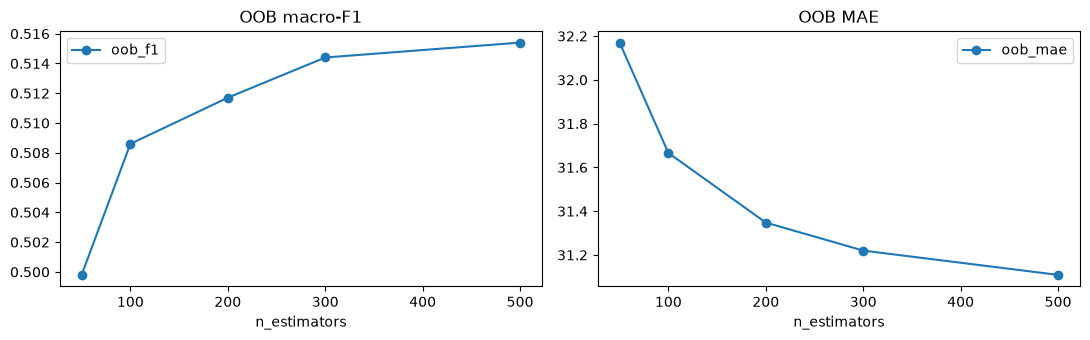

,n_estimators,oob_f1,oob_mae
0,50,0.4998,32.170
1,100,0.5086,31.666
2,200,0.5117,31.348
3,300,0.5144,31.220
4,500,0.5154,31.109


In [11]:
# H4: OOB-оценка качества в зависимости от числа деревьев (warm_start наращивает лес без переобучения с нуля)
best_c = grid.loc[grid["cv_f1"].idxmax()]
best_r = grid.loc[grid["cv_mae"].idxmin()]
mf = lambda v: v if v == "sqrt" else float(v)
pc = dict(max_features=mf(best_c["max_features"]), min_samples_leaf=int(best_c["min_samples_leaf"]))
pr = dict(max_features=mf(best_r["max_features"]), min_samples_leaf=int(best_r["min_samples_leaf"]))
oob = []
fc = RandomForestClassifier(**pc, oob_score=True, warm_start=True, random_state=SEED, n_jobs=-1)
fr = RandomForestRegressor(**pr, oob_score=True, warm_start=True, random_state=SEED, n_jobs=-1)
for n in [50, 100, 200, 300, 500]:
    fc.set_params(n_estimators=n).fit(Sa_tr, ya_tr)
    fr.set_params(n_estimators=n).fit(SMf_tr, yf_tr)
    oob.append({"n_estimators": n,
                "oob_f1": clf_metrics(ya_tr, fc.classes_[fc.oob_decision_function_.argmax(1)])["f1_macro"],
                "oob_mae": reg_metrics(yf_tr, fr.oob_prediction_)["mae"]})
oob = pd.DataFrame(oob)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
oob.plot(x="n_estimators", y="oob_f1", marker="o", ax=ax[0], title="OOB macro-F1")
oob.plot(x="n_estimators", y="oob_mae", marker="o", ax=ax[1], title="OOB MAE"); plt.tight_layout(); plt.show()
oob

### 3.3-3.5 Улучшенный бейзлайн
Плотные признаки, лучшие по CV `max_features` и `min_samples_leaf`, 300 деревьев (плато по OOB).

In [12]:
# Обучение улучшенных лесов на всём train и оценка на тесте
print(pc, pr)
rf_c2 = RandomForestClassifier(n_estimators=300, **pc, random_state=SEED, n_jobs=-1).fit(Sa_tr, ya_tr)
res["classification"]["improved"] = clf_metrics(ya_te, rf_c2.predict(Sa_te))
rf_r2 = RandomForestRegressor(n_estimators=300, **pr, random_state=SEED, n_jobs=-1).fit(SMf_tr, yf_tr)
res["regression"]["improved"] = reg_metrics(yf_te, rf_r2.predict(SMf_te))
results_table(res)

{'max_features': 0.3, 'min_samples_leaf': 10} {'max_features': 0.3, 'min_samples_leaf': 3}


,задача,этап,f1_macro,accuracy,mae,rmse,r2
0,classification,baseline,0.4684,0.5007,NaN,NaN,NaN
1,classification,improved,0.5056,0.5307,NaN,NaN,NaN
2,regression,baseline,NaN,NaN,30.42,39.183,0.1561
3,regression,improved,NaN,NaN,30.25,39.021,0.1631


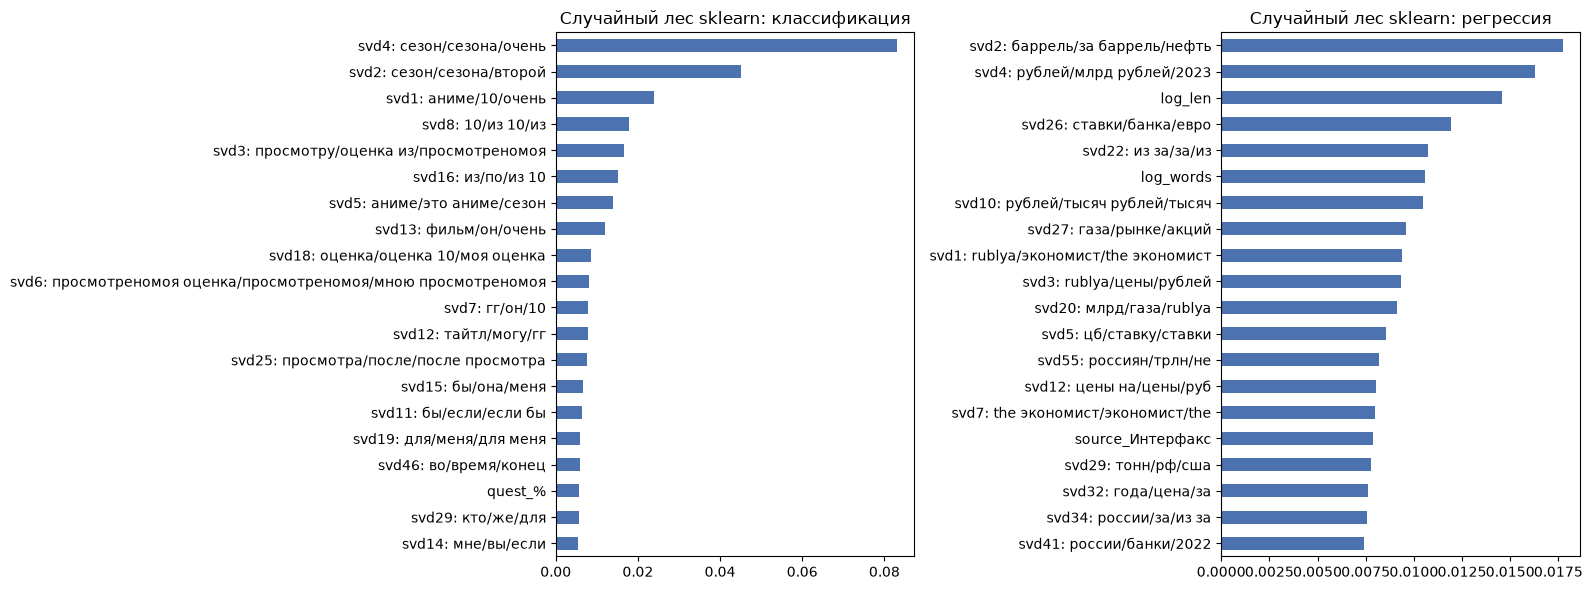

In [13]:
# Важность признаков улучшенных лесов sklearn (среднее уменьшение неоднородности по всем деревьям)
names_c = FEATURE_NAMES["anime"]
names_r = FEATURE_NAMES["finnews"] + FEATURE_NAMES["meta"]
fig, ax = plt.subplots(1, 2, figsize=(16, 6))
plot_importance(rf_c2.feature_importances_, names_c, "Случайный лес sklearn: классификация", ax=ax[0])
plot_importance(rf_r2.feature_importances_, names_r, "Случайный лес sklearn: регрессия", ax=ax[1])
plt.tight_layout(); plt.show()

### 3.7 Выводы по улучшению

- **H1 (плотные признаки) подтверждена:** лес на LSA+статистиках даёт CV macro-F1 0.495 против 0.469 на TF-IDF-1000, CV MAE 31.87 против 32.12; метаданные добавляют совсем немного.
- **H2 (декорреляция через max_features) - частично.** Для классификации **большее** число признаков в узле (0.3 = 61 признак) лучше, чем sqrt (14): CV 0.507 против 0.495 - при плотных и информативно неоднородных LSA-признаках важнее найти хорошее разбиение. Для регрессии 0.3 лучше, чем все признаки по умолчанию (бейзлайн), - меньше корреляция деревьев.
- **H3 (размер листа) подтверждена:** лучшие конфигурации - `min_samples_leaf=10` для классификации и 3 для регрессии; сглаживание листьев снижает шум отдельных деревьев.
- **H4 (число деревьев) подтверждена:** OOB macro-F1 растёт с 0.500 (50 деревьев) до 0.514 (300) и 0.515 (500), OOB MAE - с 32.17 до 31.22 / 31.11. 300 деревьев - разумный компромисс.
- Важность признаков: для отзывов - LSA-компоненты про сезоны/сиквелы, "аниме/10/очень", оценки "10 из 10" и доля "?"; для новостей - нефть/баррель, рубли/млрд, длина статьи, ставки/банки, источник "Интерфакс".
- Итог: macro-F1 **0.468 -> 0.506**, MAE **30.42 -> 30.25**. Регрессионный бейзлайн уже был силён: лес из 100 деревьев на всех признаках хорошо усредняет шумные TF-IDF-признаки.

## 4. Собственная реализация случайного леса

Лес = **бэггинг** деревьев из ЛР3 (ячейка с деревом ниже) + **случайное подпространство признаков в
каждом узле** (`max_features`). Детали:
- признаки бинируются один раз на весь лес (`Binner`), каждое дерево получает бутстрэп-подвыборку уже готовых
  кодов бинов - это экономит время и память;
- деревья обучаются параллельно в отдельных процессах (`joblib`);
- классификация - усреднение долей классов в листьях по деревьям (soft voting, как в sklearn), регрессия -
  среднее предсказаний.

In [14]:
# Гистограммное решающее дерево CART (одинаковое в ЛР3-ЛР5)
import numpy as np


class Binner:
    """Переводит вещественные признаки в номера квантильных бинов (uint8)."""

    def __init__(self, n_bins=32):
        self.n_bins = n_bins

    def fit(self, X):
        qs = np.linspace(0, 1, self.n_bins + 1)[1:-1]
        self.edges = [np.unique(np.quantile(X[:, j], qs)) for j in range(X.shape[1])]
        return self

    def transform(self, X):
        # code <= b  <=>  x <= edges[b]
        return np.stack([np.searchsorted(e, X[:, j], side="left") for j, e in enumerate(self.edges)],
                        axis=1).astype(np.uint8)


class HistTree:
    """Гистограммное дерево. G - цели/градиенты (n, K), H - гессианы (n, K) или None (=1).

    Значение листа = sum(G) / (sum(H) + reg_lambda); при H=1, lambda=0 это среднее.
    """

    def __init__(self, max_depth=8, min_samples_leaf=20, max_features=None, reg_lambda=0.0,
                 n_bins=32, random_state=None):
        self.max_depth = max_depth
        self.min_samples_leaf = min_samples_leaf
        self.max_features = max_features
        self.reg_lambda = reg_lambda
        self.n_bins = n_bins
        self.rng = np.random.default_rng(random_state)

    def fit(self, X, G, H=None, binner=None, codes=None):
        G = np.asarray(G, dtype=float)
        if G.ndim == 1:
            G = G[:, None]
        H = np.ones_like(G) if H is None else np.asarray(H, dtype=float).reshape(G.shape)
        self.binner = binner or Binner(self.n_bins).fit(X)
        C = codes if codes is not None else self.binner.transform(X)
        n, F = C.shape
        self.B = max(len(e) for e in self.binner.edges) + 1
        offsets = (np.arange(F) * self.B).astype(np.int64)
        # max_features: None - все признаки, float - доля, int - количество (случайно в каждом узле)
        mf = self.max_features
        k_feat = F if mf is None else max(1, int(mf * F)) if isinstance(mf, float) else int(mf)
        max_depth = np.inf if self.max_depth is None else self.max_depth

        # Узлы хранятся в плоских списках: признак, порог, левый/правый потомок, значение листа
        self.feat, self.thr, self.left, self.right, self.value = [], [], [], [], []
        # Важность признака = суммарное уменьшение SSE (для классификации - Джини) в его разбиениях
        self.importances_ = np.zeros(F)

        def new_node(idx):
            self.feat.append(-1); self.thr.append(0.0); self.left.append(-1); self.right.append(-1)
            self.value.append(G[idx].sum(0) / (H[idx].sum(0) + self.reg_lambda))
            return len(self.feat) - 1

        stack = [(np.arange(n), new_node(np.arange(n)), 0)]
        while stack:
            idx, node, depth = stack.pop()
            m = len(idx)
            if depth >= max_depth or m < 2 * self.min_samples_leaf:
                continue
            feats = np.arange(F) if k_feat >= F else np.sort(self.rng.choice(F, k_feat, replace=False))
            flat = (C[idx][:, feats].astype(np.int64) + offsets[: len(feats)]).ravel()
            size = len(feats) * self.B
            # Гистограммы: число объектов и суммы целей в каждом (признак, бин)
            cnt = np.bincount(flat, minlength=size).reshape(len(feats), self.B)
            g = G[idx]
            sums = np.stack([np.bincount(flat, weights=np.repeat(g[:, k], len(feats)), minlength=size)
                             .reshape(len(feats), self.B) for k in range(g.shape[1])], axis=-1)
            # Накопленные суммы = статистики левой части для порога "бин <= b"
            nL = np.cumsum(cnt, axis=1)[:, :-1]
            SL = np.cumsum(sums, axis=1)[:, :-1]
            S = g.sum(0)
            nR = m - nL
            SR = S - SL
            with np.errstate(divide="ignore", invalid="ignore"):
                gain = (SL ** 2).sum(-1) / nL + (SR ** 2).sum(-1) / nR - (S ** 2).sum() / m
            gain[(nL < self.min_samples_leaf) | (nR < self.min_samples_leaf)] = -np.inf
            gain = np.nan_to_num(gain, nan=-np.inf)
            fi, b = np.unravel_index(np.argmax(gain), gain.shape)
            if not np.isfinite(gain[fi, b]) or gain[fi, b] <= 1e-12:
                continue
            f = feats[fi]
            self.importances_[f] += gain[fi, b]
            mask = C[idx, f] <= b
            self.feat[node] = int(f)
            self.thr[node] = float(self.binner.edges[f][b])
            li, ri = idx[mask], idx[~mask]
            self.left[node], self.right[node] = new_node(li), new_node(ri)
            stack.append((li, self.left[node], depth + 1))
            stack.append((ri, self.right[node], depth + 1))

        self.feat, self.thr = np.array(self.feat), np.array(self.thr)
        self.left, self.right = np.array(self.left), np.array(self.right)
        self.value = np.array(self.value)
        return self

    def predict_raw(self, X):
        """Спуск всех объектов по дереву одновременно (векторно по уровням)."""
        node = np.zeros(len(X), dtype=np.int64)
        active = self.feat[node] >= 0
        while active.any():
            a = np.where(active)[0]
            nd = node[a]
            go_left = X[a, self.feat[nd]] <= self.thr[nd]
            node[a] = np.where(go_left, self.left[nd], self.right[nd])
            active[a] = self.feat[node[a]] >= 0
        return self.value[node]

    @property
    def feature_importances_(self):
        return self.importances_ / max(self.importances_.sum(), 1e-12)

    @property
    def n_leaves(self):
        return int((self.feat < 0).sum())


class MyDecisionTreeClassifier:
    """Классификатор: дерево на one-hot целях, предсказание - класс с максимальной долей в листе."""

    def __init__(self, **kw):
        self.kw = kw

    def fit(self, X, y, **fit_kw):
        self.classes_ = np.unique(y)
        Y = (y[:, None] == self.classes_[None, :]).astype(float)
        self.tree_ = HistTree(**self.kw).fit(X, Y, **fit_kw)
        return self

    def predict_proba(self, X):
        return self.tree_.predict_raw(X)

    def predict(self, X):
        return self.classes_[self.predict_proba(X).argmax(1)]


class MyDecisionTreeRegressor:
    """Регрессор: значение листа - среднее целевой переменной."""

    def __init__(self, **kw):
        self.kw = kw

    def fit(self, X, y, **fit_kw):
        self.tree_ = HistTree(**self.kw).fit(X, y, **fit_kw)
        return self

    def predict(self, X):
        return self.tree_.predict_raw(X)[:, 0]

In [15]:
def _fit_tree(codes, G, binner, idx, seed, params):
    # Одно дерево леса на бутстрэп-выборке idx (выполняется в отдельном процессе)
    return HistTree(random_state=seed, **params).fit(None, G[idx], binner=binner, codes=codes[idx])


class MyRandomForest:
    """Случайный лес: task='clf' (one-hot цели, soft voting) или 'reg'."""

    def __init__(self, n_estimators=100, max_features="sqrt", max_depth=None, min_samples_leaf=1,
                 task="clf", n_bins=32, n_jobs=-1, random_state=0):
        self.n_estimators, self.max_features, self.task = n_estimators, max_features, task
        self.tree_params = dict(max_depth=max_depth, min_samples_leaf=min_samples_leaf)
        self.n_bins, self.n_jobs, self.random_state = n_bins, n_jobs, random_state

    def fit(self, X, y):
        n, F = X.shape
        if self.task == "clf":
            self.classes_ = np.unique(y)
            G = (y[:, None] == self.classes_).astype(float)
        else:
            G = np.asarray(y, float)[:, None]
        # max_features: 'sqrt' -> int(sqrt(F)), float -> доля, None -> все признаки
        mf = int(np.sqrt(F)) if self.max_features == "sqrt" else self.max_features
        params = dict(self.tree_params, max_features=mf, n_bins=self.n_bins)
        binner = Binner(self.n_bins).fit(X)
        codes = binner.transform(X)
        rng = np.random.default_rng(self.random_state)
        boots = [rng.integers(0, n, n) for _ in range(self.n_estimators)]       # бутстрэп-индексы
        seeds = rng.integers(0, 2**31, self.n_estimators)
        self.trees_ = Parallel(n_jobs=self.n_jobs)(
            delayed(_fit_tree)(codes, G, binner, b, s, params) for b, s in zip(boots, seeds))
        return self

    @property
    def feature_importances_(self):
        # Средняя по деревьям нормированная важность (как в sklearn)
        return np.mean([t.feature_importances_ for t in self.trees_], axis=0)

    def _raw(self, X):
        # Усреднение выходов всех деревьев
        return np.mean([t.predict_raw(X) for t in self.trees_], axis=0)

    def predict(self, X):
        out = self._raw(X)
        return self.classes_[out.argmax(1)] if self.task == "clf" else out[:, 0]

### 4.2-4.3 Собственная реализация с параметрами бейзлайна
TF-IDF (1000 слов), 100 деревьев без ограничения глубины, `min_samples_leaf=1`, `max_features`: sqrt / все признаки.

In [16]:
# Обучение и оценка собственного леса в конфигурации бейзлайна
my_c = MyRandomForest(100, max_features="sqrt", task="clf", random_state=SEED).fit(Ad_tr, ya_tr)
res["classification"]["custom"] = clf_metrics(ya_te, my_c.predict(Ad_te))
my_r = MyRandomForest(100, max_features=None, task="reg", random_state=SEED).fit(Fd_tr, yf_tr)
res["regression"]["custom"] = reg_metrics(yf_te, my_r.predict(Fd_te))
results_table({t: {s: d[s] for s in ["baseline", "custom"]} for t, d in res.items()})

,задача,этап,f1_macro,accuracy,mae,rmse,r2
0,classification,baseline,0.4684,0.5007,NaN,NaN,NaN
1,classification,custom,0.4514,0.4885,NaN,NaN,NaN
2,regression,baseline,NaN,NaN,30.42,39.183,0.1561
3,regression,custom,NaN,NaN,30.58,39.344,0.1492


### 4.5 Выводы

Собственный лес (бэггинг гистограммных деревьев + случайное подпространство признаков в каждом узле) в конфигурации бейзлайна немного уступает sklearn: macro-F1 0.451 против 0.468, MAE 30.58 против 30.42. Причина - бинирование: у TF-IDF-признаков большинство значений нулевые, и 32 квантильных бина хуже описывают ненулевую часть распределения, чем точные пороги sklearn. На разреженных признаках это заметнее, чем у одиночного дерева, потому что каждое дерево леса видит лишь 31 случайный признак в узле.

### 4.6-4.8 Собственная реализация + техники улучшенного бейзлайна

In [17]:
# Собственный лес: плотные признаки, подобранные max_features / min_samples_leaf, 300 деревьев
my_c2 = MyRandomForest(300, **pc, task="clf", random_state=SEED).fit(Sa_tr, ya_tr)
res["classification"]["custom_improved"] = clf_metrics(ya_te, my_c2.predict(Sa_te))
my_r2 = MyRandomForest(300, **pr, task="reg", random_state=SEED).fit(SMf_tr, yf_tr)
res["regression"]["custom_improved"] = reg_metrics(yf_te, my_r2.predict(SMf_te))
results_table({t: {s: d[s] for s in ["improved", "custom_improved"]} for t, d in res.items()})

,задача,этап,f1_macro,accuracy,mae,rmse,r2
0,classification,improved,0.5056,0.5307,NaN,NaN,NaN
1,classification,custom_improved,0.5026,0.5288,NaN,NaN,NaN
2,regression,improved,NaN,NaN,30.25,39.021,0.1631
3,regression,custom_improved,NaN,NaN,30.21,39.052,0.1617


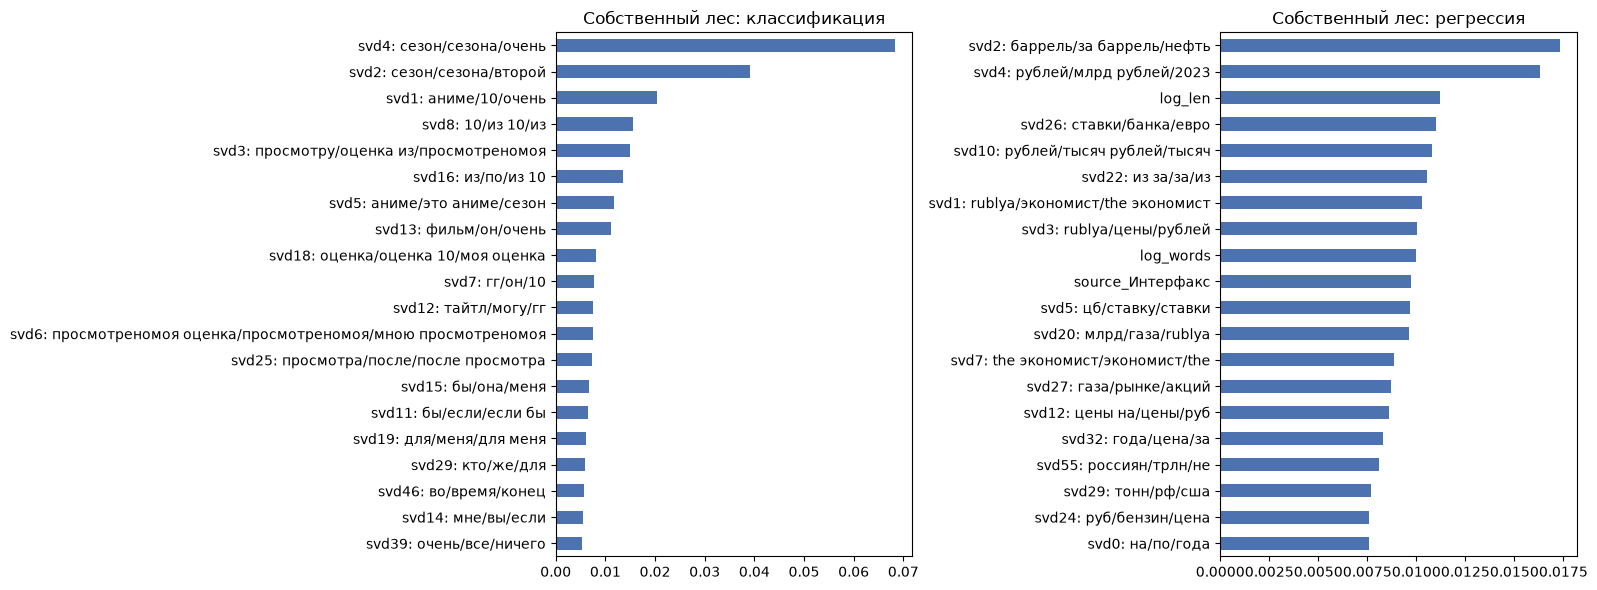

In [18]:
# Важность признаков собственного леса
fig, ax = plt.subplots(1, 2, figsize=(16, 6))
plot_importance(my_c2.feature_importances_, names_c, "Собственный лес: классификация", ax=ax[0])
plot_importance(my_r2.feature_importances_, names_r, "Собственный лес: регрессия", ax=ax[1])
plt.tight_layout(); plt.show()

### 4.10 Выводы

На плотных LSA-признаках бинирование почти не теряет информацию, и собственный лес догоняет sklearn: macro-F1 **0.503** против 0.506, MAE **30.21** против 30.25 (даже немного лучше). Важности признаков собственного леса совпадают с sklearn по составу лидеров.

## Сравнение всех этапов

Сводная таблица метрик на тестовой выборке: бейзлайн (п.2), улучшенный бейзлайн (п.3), собственная реализация (п.4) и собственная реализация с техниками улучшенного бейзлайна.

In [19]:
# Таблица метрик по всем этапам и сохранение в labs/results/LR4.json для итогового ноутбука
table = results_table(res)
save_results("LR4", res)
table

,задача,этап,f1_macro,accuracy,mae,rmse,r2
0,classification,baseline,0.4684,0.5007,NaN,NaN,NaN
1,classification,improved,0.5056,0.5307,NaN,NaN,NaN
2,classification,custom,0.4514,0.4885,NaN,NaN,NaN
3,classification,custom_improved,0.5026,0.5288,NaN,NaN,NaN
4,regression,baseline,NaN,NaN,30.42,39.183,0.1561
5,regression,improved,NaN,NaN,30.25,39.021,0.1631
6,regression,custom,NaN,NaN,30.58,39.344,0.1492
7,regression,custom_improved,NaN,NaN,30.21,39.052,0.1617


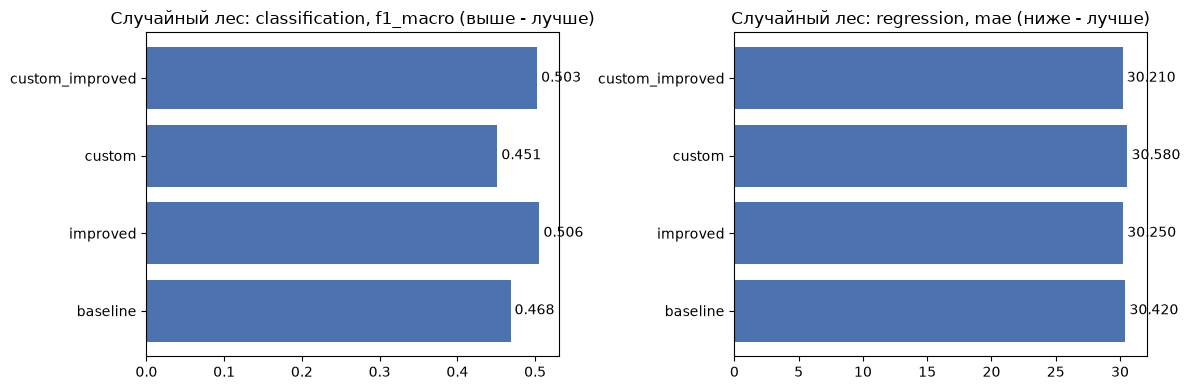

In [20]:
# Визуальное сравнение основной метрики каждой задачи по этапам
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for a, (task, metric) in zip(ax, [("classification", "f1_macro"), ("regression", "mae")]):
    t = table[table["задача"] == task]
    a.barh(t["этап"], t[metric], color="#4C72B0")
    a.set_title(f"Случайный лес: {task}, {metric}" + (" (выше - лучше)" if metric == "f1_macro" else " (ниже - лучше)"))
    for i, v in enumerate(t[metric]):
        a.text(v, i, f" {v:.3f}", va="center")
plt.tight_layout(); plt.show()

## Выводы

1. Случайный лес заметно лучше одиночного дерева (macro-F1 0.506 против 0.472, MAE 30.2 против 31.7): усреднение декоррелированных деревьев убирает переобучение.
2. Но лес уступает линейным моделям (0.597 / 29.33) и бустингу: на текстах сигнал распределён по многим слабым признакам, а случайные подпространства и глубокие деревья используют его менее эффективно.
3. Собственная реализация совпадает со sklearn на плотных признаках и чуть уступает на разреженных из-за гистограммных порогов.